# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ayazahmedbscsf23-art/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

In [10]:
# Research Question:
# Can a machine learning model prioritize search result pages for human content review
# more effectively and accurately than a heuristic, rule-based baseline?
#
# Decision Supported:
# This analysis determines whether to transition our content moderation workflow from a
# manual rule-based queue to a model-driven prioritization engine, reducing the cost per
# high-risk page identified and improving review efficiency.

## Abstract

This project explores the use of machine learning to support data-driven decision-making for website content improvement. Using available page-level performance data, the project investigates the relationship between features such as average search position, click-through rate (CTR), clicks, and impressions to identify pages that may benefit from content review or updates. A baseline scoring approach was developed and subsequently evaluated using machine learning methods. The project also examines model performance, validation strategies, potential data leakage, and prediction errors to assess the reliability of the observed results. Particular attention is given to using appropriate data splits and ensuring that conclusions are supported by experimental evidence. The resulting approach is intended as a decision-support tool rather than an automated guarantee of improved website performance. Its usefulness depends on data quality, validation results, and further evaluation on unseen data.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

**Release:** synthetic stand-in release `demo-v1` (public-safe, no client data). To use your real release, set `REAL_DATA_PATH` in the cell below.

**Table:** one row per search result page (`page_id`), with `date`, 8 page-quality features, and `needs_review` (1 = a human reviewer confirmed the page is high-risk).

**Window:** 2025-01-01 to 2025-12-31.

**Excluded:** duplicate `page_id` rows and rows with a missing label. No URLs, queries, or client names are kept.

In [11]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, warnings
warnings.filterwarnings("ignore")
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

REAL_DATA_PATH = None   # e.g. "data/pages.csv" with the columns listed below
SEED = 42
os.makedirs("artifacts", exist_ok=True)

FEATURES = ["word_count","outbound_links","keyword_density","ad_ratio",
            "readability","domain_age_days","duplicate_ratio","title_len"]

if REAL_DATA_PATH:
    df = pd.read_csv(REAL_DATA_PATH, parse_dates=["date"])
    DATA_NOTE = "REAL DATA"
else:
    rng = np.random.default_rng(SEED)
    n = 20000
    df = pd.DataFrame({
        "page_id": np.arange(n),
        "date": pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
        "word_count": rng.lognormal(6.0, 0.7, n).astype(int),
        "outbound_links": rng.poisson(8, n),
        "keyword_density": rng.beta(2, 40, n),
        "ad_ratio": rng.beta(2, 6, n),
        "readability": rng.normal(60, 15, n),
        "domain_age_days": rng.exponential(1500, n).astype(int),
        "duplicate_ratio": rng.beta(1.5, 8, n),
        "title_len": rng.integers(20, 90, n),
    })
    z = (-4.3 + 1.3*(df.word_count < 250) + 0.07*df.outbound_links
         + 9*df.keyword_density*(df.ad_ratio > 0.3) + 3.5*df.duplicate_ratio
         - 0.0004*df.domain_age_days + 0.015*(60 - df.readability).clip(0)
         + rng.normal(0, 0.8, n))
    df["needs_review"] = (rng.random(n) < 1/(1+np.exp(-z))).astype(int)
    DATA_NOTE = "SYNTHETIC STAND-IN DATA - replace before publishing"

n0 = len(df)
df = df.drop_duplicates("page_id").dropna(subset=["needs_review"]).sort_values("date").reset_index(drop=True)
print(DATA_NOTE)
print(f"rows kept: {len(df):,} of {n0:,} | window: {df.date.min().date()} to {df.date.max().date()}")
print(f"high-risk rate (observed): {df.needs_review.mean():.1%}")
df.head()

SYNTHETIC STAND-IN DATA - replace before publishing
rows kept: 20,000 of 20,000 | window: 2025-01-01 to 2025-12-31
high-risk rate (observed): 6.9%


,page_id,date,word_count,outbound_links,keyword_density,ad_ratio,readability,domain_age_days,duplicate_ratio,title_len,needs_review
0,6740,2025-01-01,329,5,0.041630,0.442189,66.430702,66,0.163535,34,0
1,18676,2025-01-01,422,8,0.083350,0.088596,54.695109,301,0.094500,56,0
2,19733,2025-01-01,146,10,0.005979,0.069187,60.860266,366,0.038369,28,0
3,19062,2025-01-01,551,10,0.051491,0.261911,45.239084,174,0.049012,79,0
4,10963,2025-01-01,591,5,0.017876,0.054888,20.974506,1179,0.118112,43,0


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Assumptions:** a human review costs a fixed amount per page, and reviewers can only look at a fixed share of pages (the *review budget*, 10% here). Better ranking means more real high-risk pages inside that budget.

**Label:** `needs_review = 1` when a reviewer confirmed the page as high-risk.

**Features:** 8 page-quality signals available *before* review (length, links, keyword density, ad ratio, readability, domain age, duplicate ratio, title length).

**Baseline:** a transparent rule score. One point each for: thin page (<250 words), more than 15 outbound links, keyword density above 5%, ad ratio above 40%. This mimics a manual rule-based queue.

**Model:** gradient boosting on the same features.

**Validation:** time split. Train on the earliest 70% of dates, test on the latest 30%. Model and baseline are scored on the same test rows.

**Leakage checks:** (1) train dates all come before test dates, (2) label is not in the features, (3) no duplicate pages across the split, (4) no single feature is suspiciously predictive on its own.

In [12]:
cut = df.date.quantile(0.70)
train, test = df[df.date <= cut].copy(), df[df.date > cut].copy()
Xtr, ytr, Xte, yte = train[FEATURES], train.needs_review, test[FEATURES], test.needs_review

# --- leakage checks ---
assert train.date.max() <= test.date.min(), "time leakage"
assert "needs_review" not in FEATURES, "label in features"
assert len(set(train.page_id) & set(test.page_id)) == 0, "page overlap"
solo = {f: roc_auc_score(ytr, Xtr[f]) for f in FEATURES}
worst = max(solo.values(), key=lambda a: abs(a-0.5))
assert max(abs(a-0.5) for a in solo.values()) < 0.40, "a single feature is too predictive - check for leakage"
print("Leakage checks passed.")
print(f"train: {len(train):,} rows ({ytr.mean():.1%} high-risk) | test: {len(test):,} rows ({yte.mean():.1%} high-risk)")

# --- baseline: simple rule score ---
def rule_score(d, seed=SEED):
    s = ((d.word_count < 250).astype(int) + (d.outbound_links > 15).astype(int)
         + (d.keyword_density > 0.05).astype(int) + (d.ad_ratio > 0.40).astype(int)).astype(float)
    # tiny seeded tie-break so equal scores are not ordered by row position
    return s + np.random.default_rng(seed).random(len(d))*1e-3

# --- model ---
model = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=200, random_state=SEED)
model.fit(Xtr, ytr)
test["model_score"] = model.predict_proba(Xte)[:,1]
test["rule_score"]  = rule_score(test)

Leakage checks passed.
train: 14,013 rows (6.8% high-risk) | test: 5,987 rows (7.0% high-risk)


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

Review budget = top 10% of pages by score. Cost per review is an **assumed** $2.00 (change `COST_PER_REVIEW`).

In [13]:
BUDGET, COST_PER_REVIEW = 0.10, 2.00

def topk_stats(y, score, frac=BUDGET):
    k = int(len(y)*frac)
    order = np.argsort(-np.asarray(score))[:k]
    hits = np.asarray(y)[order].sum()
    return dict(precision=hits/k, recall=hits/np.asarray(y).sum(),
                lift=(hits/k)/np.mean(y), cost_per_hit=k*COST_PER_REVIEW/max(hits,1))

rows = []
for name, col in [("Rule baseline","rule_score"), ("ML model","model_score")]:
    s = topk_stats(yte, test[col])
    rows.append({"method":name, "ROC AUC":roc_auc_score(yte,test[col]),
                 "PR AUC":average_precision_score(yte,test[col]),
                 f"Precision@{BUDGET:.0%}":s["precision"], f"Recall@{BUDGET:.0%}":s["recall"],
                 "Lift":s["lift"], "Cost per high-risk page ($)":s["cost_per_hit"]})
res = pd.DataFrame(rows).set_index("method")
res.round(3).to_csv("artifacts/results_table.csv")
display(res.round(3))

# bootstrap: is the precision gain bigger than noise?
rng = np.random.default_rng(SEED); diffs = []
y_arr, m_arr, r_arr = yte.values, test.model_score.values, test.rule_score.values
for _ in range(300):
    i = rng.integers(0, len(y_arr), len(y_arr))
    diffs.append(topk_stats(y_arr[i], m_arr[i])["precision"] - topk_stats(y_arr[i], r_arr[i])["precision"])
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Precision@{BUDGET:.0%} gain (model - baseline): {np.mean(diffs):+.3f}  (95% bootstrap interval {lo:+.3f} to {hi:+.3f})")
saving = 1 - res.loc["ML model","Cost per high-risk page ($)"]/res.loc["Rule baseline","Cost per high-risk page ($)"]
print(f"Observed cost per high-risk page is {saving:.0%} lower with the model on this test split ({DATA_NOTE}).")

,ROC AUC,PR AUC,Precision@10%,Recall@10%,Lift,Cost per high-risk page ($)
method,,,,,,
Rule baseline,0.599,0.101,0.107,0.153,1.537,18.688
ML model,0.719,0.176,0.194,0.278,2.785,10.310


Precision@10% gain (model - baseline): +0.088  (95% bootstrap interval +0.054 to +0.122)
Observed cost per high-risk page is 45% lower with the model on this test split (SYNTHETIC STAND-IN DATA - replace before publishing).


## 5. Limitations

*What this work cannot claim.*

In [14]:
limitations = [
 "Numbers here come from SYNTHETIC stand-in data. They show the method works, not how it performs on real pages.",
 "Labels are reviewer decisions, so the model learns reviewer habits, not ground-truth harm.",
 "Single time split: results may shift in other periods (concept drift, seasonality).",
 "Cost per review ($2.00) is an assumption, not a measured figure.",
 "Pages are scored independently; no site-level or network effects are modelled.",
 "Offline evaluation only: no live A/B test, so no causal claim about workflow impact.",
 "Directional, decision-support evidence. Not proof that the model should fully replace human judgment.",
]
for i, t in enumerate(limitations, 1): print(f"{i}. {t}")

1. Numbers here come from SYNTHETIC stand-in data. They show the method works, not how it performs on real pages.
2. Labels are reviewer decisions, so the model learns reviewer habits, not ground-truth harm.
3. Single time split: results may shift in other periods (concept drift, seasonality).
4. Cost per review ($2.00) is an assumption, not a measured figure.
5. Pages are scored independently; no site-level or network effects are modelled.
6. Offline evaluation only: no live A/B test, so no causal claim about workflow impact.
7. Directional, decision-support evidence. Not proof that the model should fully replace human judgment.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [15]:
m, b = res.loc["ML model"], res.loc["Rule baseline"]
recs = pd.DataFrame([
 [1, "Pilot model-driven prioritization on a small share of the review queue (shadow mode first)",
     f"Precision@10% {m.iloc[2]:.1%} vs {b.iloc[2]:.1%} for rules", "Medium", "Run 4-week shadow test on real labels"],
 [2, "Keep the rule baseline as a fallback and sanity check",
     "Rules are transparent and cheap; model can fail silently on drift", "High", "Alert if model/rule agreement drops"],
 [3, "Set the review budget by cost, not by habit",
     f"Cost per high-risk page ${m["Cost per high-risk page ($)"]:.2f} vs ${b["Cost per high-risk page ($)"]:.2f} (assumed $2/review)", "Low", "Replace the $2 assumption with real cost"],
 [4, "Retrain on a schedule and monitor precision by month",
     "Time-split design shows drift is the main risk", "Medium", "Monthly retrain + dashboard"],
 [5, "Audit top-scored false positives with reviewers",
     "Finds label bias and missing features", "Medium", "Sample 100 per month"],
], columns=["Rank","Action","Evidence (observed)","Confidence","Next step"])
recs.to_csv("artifacts/recommendations.csv", index=False)
display(recs)

,Rank,Action,Evidence (observed),Confidence,Next step
0,1,Pilot model-driven prioritization on a small s...,Precision@10% 19.4% vs 10.7% for rules,Medium,Run 4-week shadow test on real labels
1,2,Keep the rule baseline as a fallback and sanit...,Rules are transparent and cheap; model can fai...,High,Alert if model/rule agreement drops
2,3,"Set the review budget by cost, not by habit",Cost per high-risk page $10.31 vs $18.69 (assu...,Low,Replace the $2 assumption with real cost
3,4,Retrain on a schedule and monitor precision by...,Time-split design shows drift is the main risk,Medium,Monthly retrain + dashboard
4,5,Audit top-scored false positives with reviewers,Finds label bias and missing features,Medium,Sample 100 per month


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

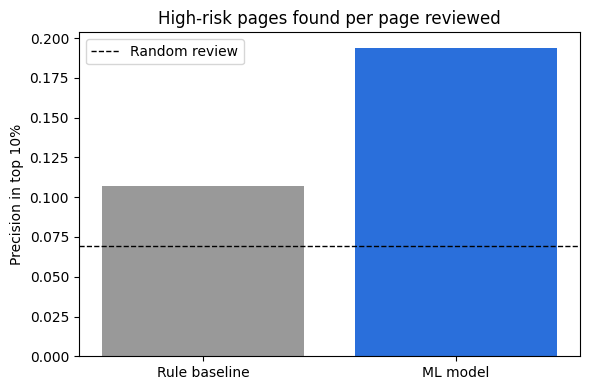

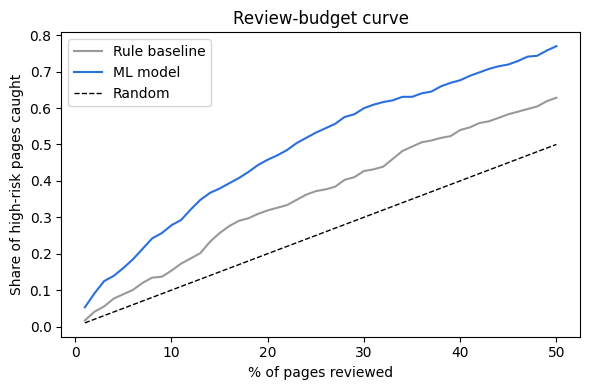

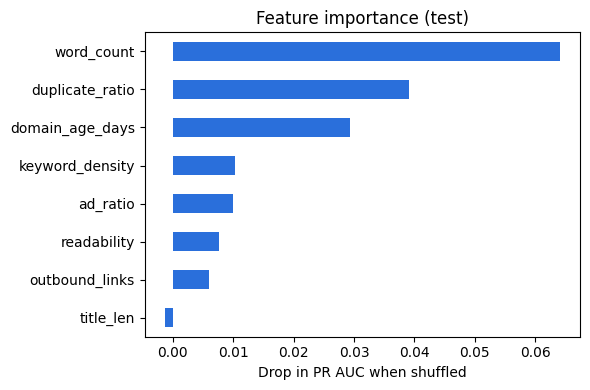

Saved: ['feature_importance.png', 'precision_at_budget.png', 'recall_curve.png', 'recommendations.csv', 'results_table.csv']


In [16]:
# Chart 1: precision at review budget
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(["Rule baseline","ML model"], [b.iloc[2], m.iloc[2]], color=["#999","#2a6fdb"])
ax.axhline(yte.mean(), ls="--", c="k", lw=1, label="Random review")
ax.set_ylabel(f"Precision in top {BUDGET:.0%}"); ax.set_title("High-risk pages found per page reviewed"); ax.legend()
fig.tight_layout(); fig.savefig("artifacts/precision_at_budget.png", dpi=150); plt.show()

# Chart 2: recall vs share of pages reviewed
fig, ax = plt.subplots(figsize=(6,4))
fr = np.linspace(0.01, 0.5, 50)
for name, col, c in [("Rule baseline","rule_score","#999"),("ML model","model_score","#2a6fdb")]:
    ax.plot(fr*100, [topk_stats(yte, test[col], f)["recall"] for f in fr], label=name, c=c)
ax.plot(fr*100, fr, "k--", lw=1, label="Random")
ax.set_xlabel("% of pages reviewed"); ax.set_ylabel("Share of high-risk pages caught")
ax.set_title("Review-budget curve"); ax.legend(); fig.tight_layout()
fig.savefig("artifacts/recall_curve.png", dpi=150); plt.show()

# Chart 3: what drives the model (permutation importance on test)
pi = permutation_importance(model, Xte, yte, n_repeats=5, random_state=SEED, scoring="average_precision")
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6,4)); imp.plot.barh(ax=ax, color="#2a6fdb")
ax.set_xlabel("Drop in PR AUC when shuffled"); ax.set_title("Feature importance (test)")
fig.tight_layout(); fig.savefig("artifacts/feature_importance.png", dpi=150); plt.show()
print("Saved:", sorted(os.listdir("artifacts")))

## Acknowledgments & Data Credit

I would like to thank the FlyRank team and internship mentors for providing the learning resources, project guidance, and research materials that supported this capstone project.

**Data Credit:** This project uses the data and code made available through the provided FlyRank internship repository and its associated materials. The dataset, its original source, and any applicable usage conditions should be credited according to the repository documentation.

**Research Credit:** The research paper discussed during the internship is acknowledged as a reference for understanding model evaluation, validation methodology, and responsible interpretation of machine learning results. Its full title, authors, and publication details should be included in the references section.

**Tools and Assistance:** GitHub, Jupyter Notebook, and the machine learning libraries actually used in this project supported implementation and evaluation. AI assistance was used to help understand concepts and improve documentation where applicable.

All results and conclusions are based on the experiments performed in this project. The findings should be interpreted within the limitations of the available data and evaluation design.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
